In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("BIED_Smart_Agriculture_Dataset.csv")
df.head()

,timestamp,device_id,location,crop_type,season,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,crop_health,yield_estimate,pest_risk,anomaly_flag
0,2024-01-01 00:00:00,BD-MYM-002,Mymensingh,Rice,winter,23.16,59.08,0.00,41.64,6.63,16.0,61.58,0,Healthy,4.29,Low,0
1,2024-01-01 00:00:00,BD-MYM-005,Mymensingh,Wheat,winter,23.79,56.87,0.00,57.24,6.57,52.0,11.52,0,Healthy,3.25,Low,0
2,2024-01-01 00:00:00,BD-RAJ-003,Rajshahi,Rice,winter,19.64,62.09,0.00,51.01,5.64,79.0,31.35,0,Healthy,4.67,Low,0
3,2024-01-01 01:00:00,BD-MYM-002,Mymensingh,Tomato,winter,18.68,52.33,14.87,75.14,6.26,68.0,24.17,0,Healthy,35.56,Low,0
4,2024-01-01 01:00:00,BD-CHA-001,Chattogram,Rice,winter,20.75,59.96,0.00,64.59,6.01,31.0,85.57,0,Healthy,4.40,Low,0


In [ ]:
df.shape

(10000, 17)

In [ ]:
df.columns

Index(['timestamp', 'device_id', 'location', 'crop_type', 'season',
       'temperature', 'humidity', 'rainfall', 'soil_moisture', 'soil_ph',
       'light_intensity', 'fertilizer_used', 'irrigation_needed',
       'crop_health', 'yield_estimate', 'pest_risk', 'anomaly_flag'],
      dtype='object')



**timestamp** — Дата и время записи

**device_id** — ID датчика

**location** — Регион Бангладеш (Mymensingh, Rajshahi, Dhaka, Khulna, Chattogram, Sylhet)

**crop_type** — Тип культуры (Rice, Wheat, Tomato, Jute)
**season** — сезон

**temperature** — температура воздуха в градусах Цельсия

**humidity** — относительная влажность воздуха в процентах

**rainfall** — количество осадков в миллиметрах

**soil_moisture** — влажность почвы в процентах

**soil_ph** — кислотность почвы по шкале pH

**light_intensity** — интенсивность света в люксах

**fertilizer_used** — количество использованных удобрений

**irrigation_needed** — бинарный признак, показывающий, нужен ли полив: 0 — не нужен, 1 — нужен

**crop_health** — Состояние культуры (Healthy / Stress / Diseased)

**yield_estimate** — оценка урожайности

**pest_risk** — риск появления вредителей

**anomaly_flag** — бинарный флаг аномалии: 0 — норма, 1 — аномалия.

In [ ]:
df.describe()

,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,yield_estimate,anomaly_flag
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,28.618411,66.692239,3.019284,47.019202,6.380495,12188.731100,30.521662,0.181500,13.134026,0.020200
std,5.399040,8.178572,8.151775,13.748611,0.502964,15317.903602,18.900354,0.385451,12.929829,0.140691
min,15.000000,40.000000,0.000000,10.000000,5.500000,0.000000,0.000000,0.000000,1.120000,0.000000
25%,23.520000,61.070000,0.000000,37.560000,6.020000,42.000000,16.280000,0.000000,3.040000,0.000000
50%,30.150000,67.010000,0.000000,46.660000,6.380000,97.000000,29.820000,0.000000,4.450000,0.000000
75%,32.890000,72.380000,0.000000,56.142500,6.740000,26307.500000,43.262500,0.000000,25.590000,0.000000
max,42.000000,95.000000,50.000000,95.000000,8.090000,50000.000000,101.130000,1.000000,38.500000,1.000000


### Пропуски

In [ ]:
df.isna().sum()

,0
timestamp,0
device_id,0
location,0
crop_type,0
season,0
temperature,0
humidity,0
rainfall,0
soil_moisture,0
soil_ph,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
timestamp,4320
device_id,48
location,6
crop_type,5
season,2
temperature,2074
humidity,3244
rainfall,1553
soil_moisture,4566
soil_ph,241


### Целевая переменная и ее распределение

crop_health — многоклассовая классификация (Healthy / Stress / Diseased);



In [ ]:
df["crop_health"].value_counts(dropna=False)

,count
crop_health,
Healthy,7418
Stressed,2034
Critical,548


In [ ]:
(df["crop_health"].value_counts(normalize=True) * 100).round(2) # доли рассчитаны среди строк с известной меткой.

,proportion
crop_health,
Healthy,74.18
Stressed,20.34
Critical,5.48


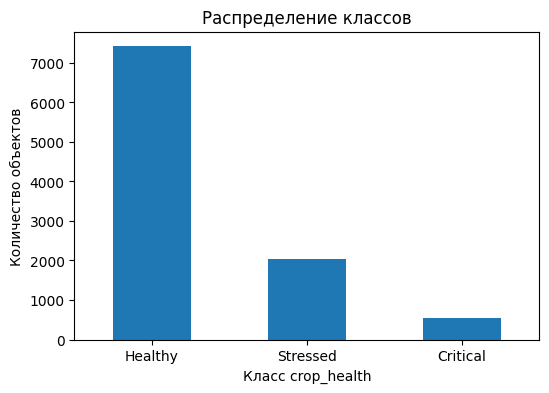

In [ ]:
df["crop_health"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Распределение классов")
plt.xlabel("Класс crop_health")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)
plt.show()

In [ ]:
(df["crop_health"].value_counts(normalize=True) * 100).round(2)

,proportion
crop_health,
Healthy,74.18
Stressed,20.34
Critical,5.48


### Распределения числовых признаков

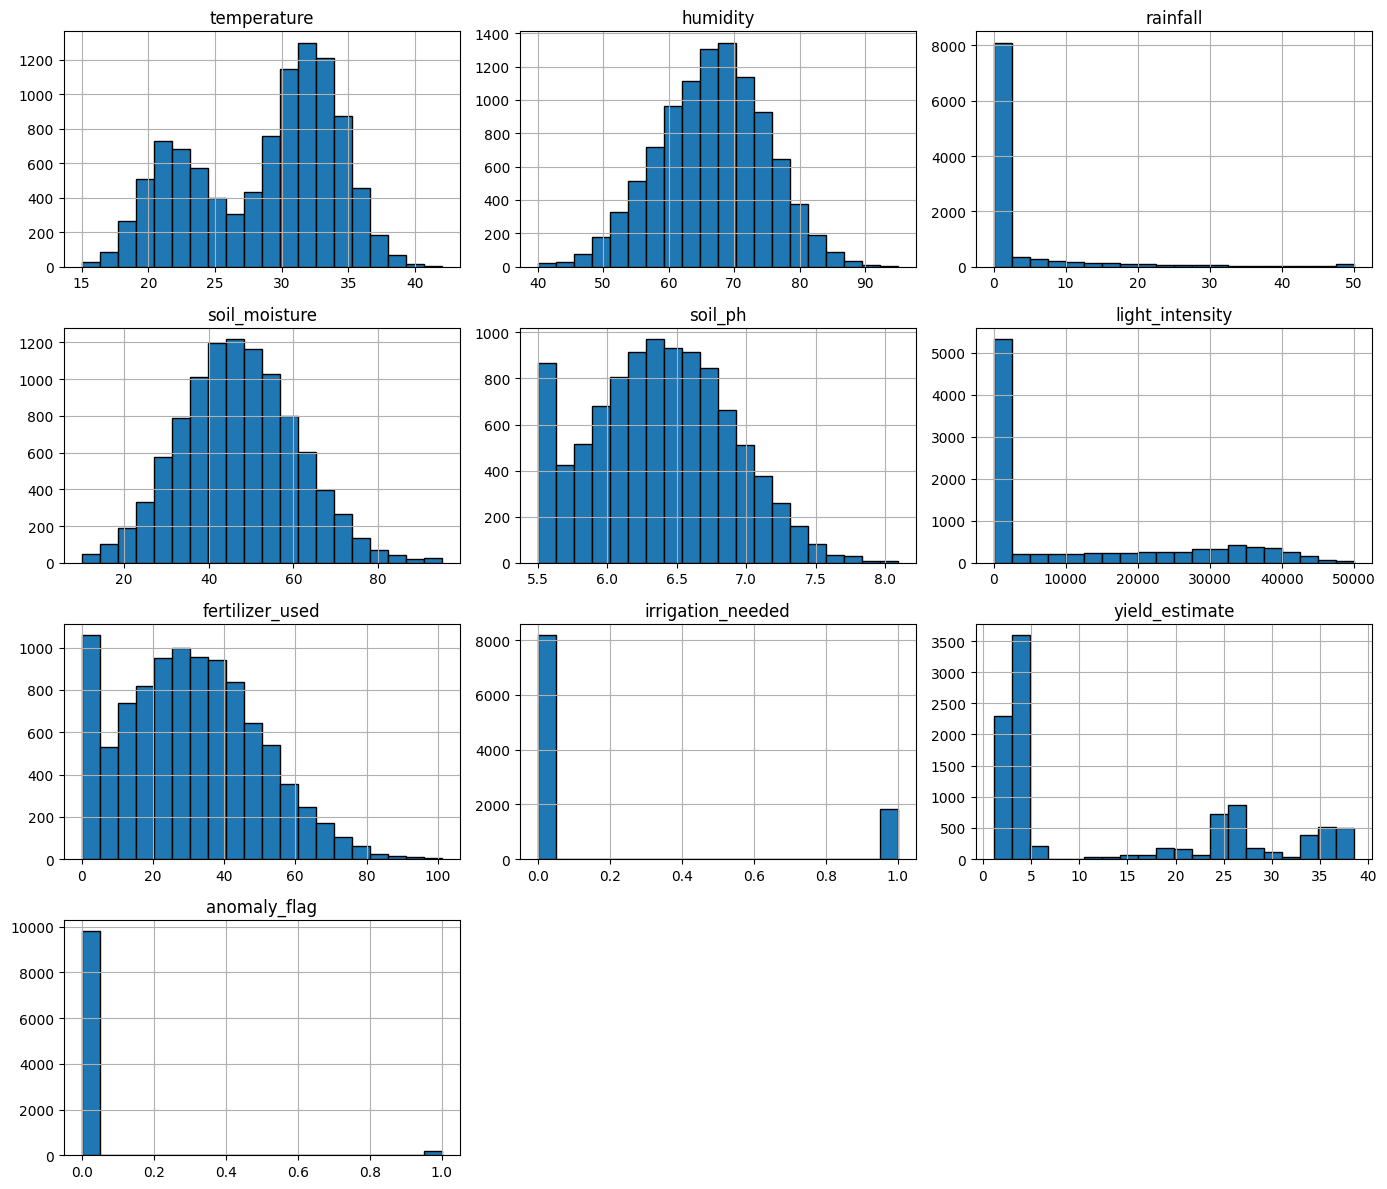

In [ ]:
numeric_df = df.select_dtypes(include="number")
features = numeric_df.drop(columns="crop_health", errors="ignore")
features.hist(bins=20, figsize=(14, 12), edgecolor="black")
plt.tight_layout()
plt.show()

temperature - двугорбое распределение с пиками около 21–22 °C и 32–33 °C.

humidity — колоколообразное, центр  около 65%. Нормально для тропического климата.

rainfall — резко скошено влево: примерно 8000 записей с нулём осадков и длинный хвост. Чаще всего дождя нет, но иногда бывает много.

light_intensity — резко скошено влево: много нулей (ночь) и хвост до 50000 люкс (день).

fertilizer_used — скошено влево, хвост до 100. Нормально.

irrigation_needed — бинарное: 0 или 1, причём 1 встречается редко (~2000 из 10000).

yield_estimate — мультимодальное с пиками около 3–5, 25 и 35–40. Это признак того, что данные генерировались по культурам: разные crop_type дают разную урожайность.

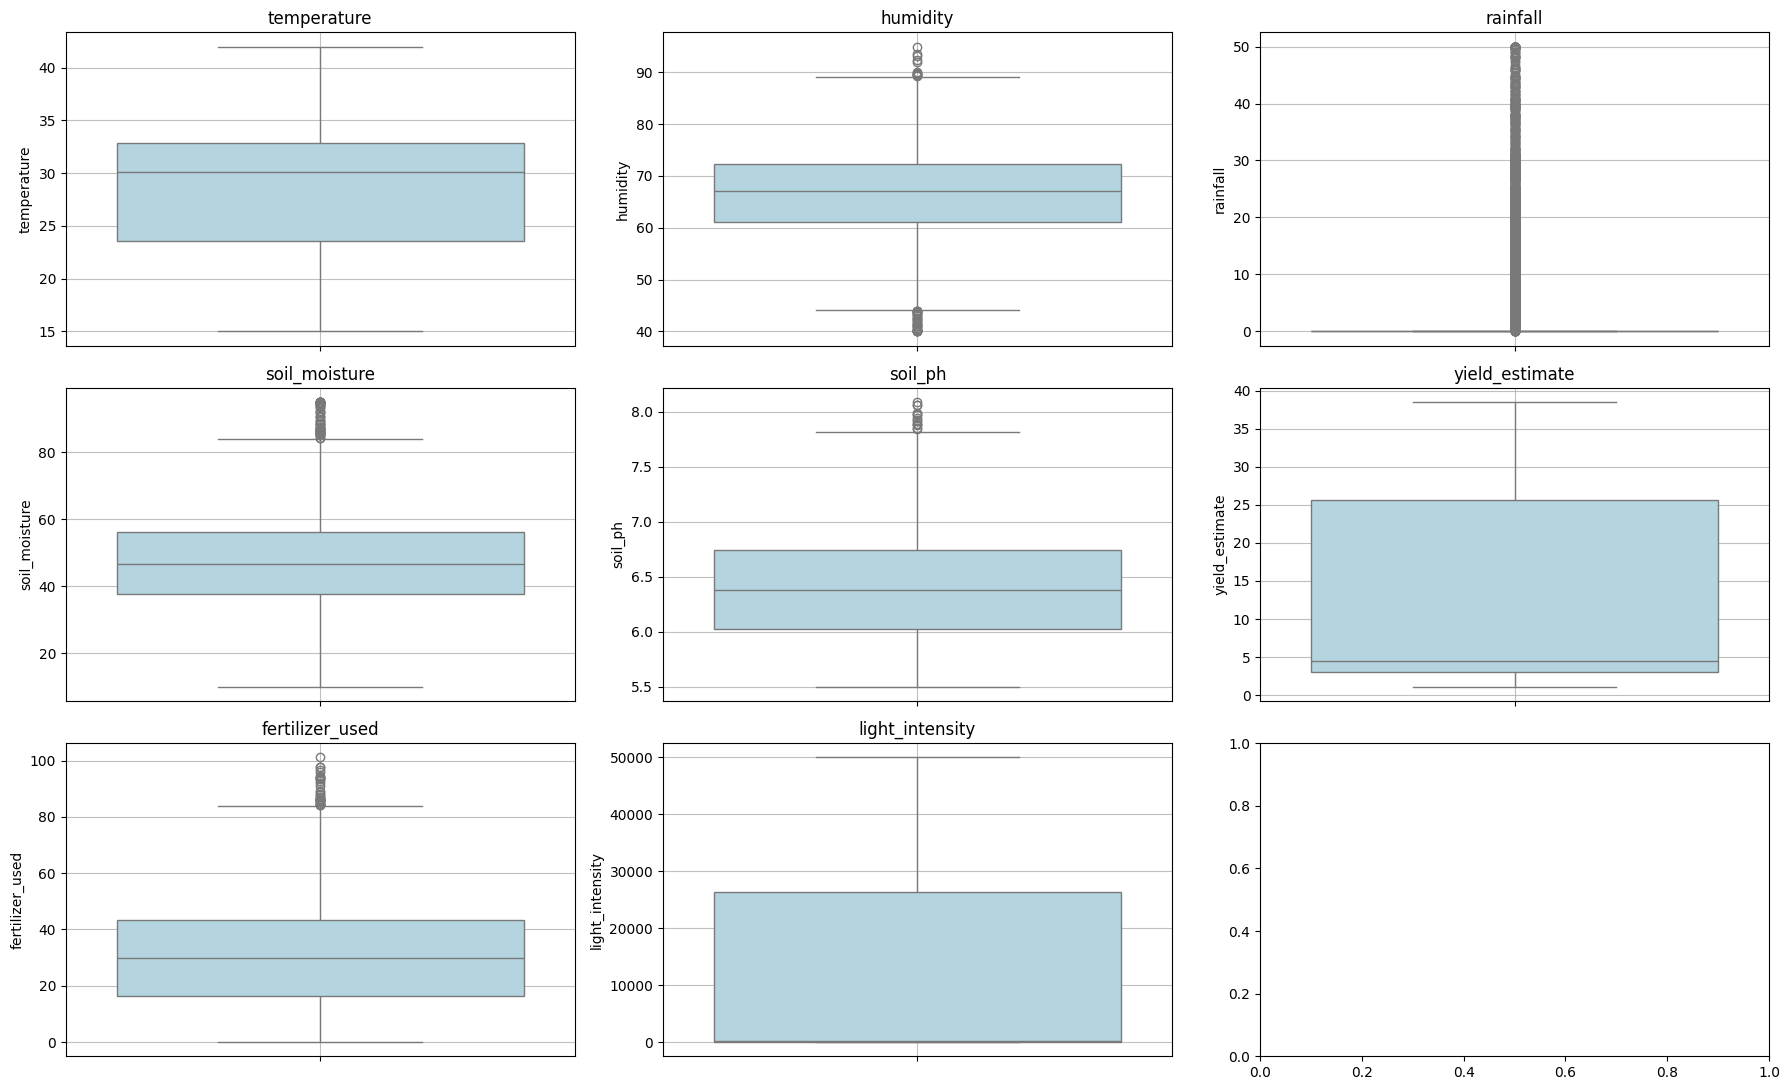

In [ ]:
cols = ["temperature", "humidity", "rainfall",
        "soil_moisture", "soil_ph", "yield_estimate", "fertilizer_used", "light_intensity"]

fig, axes = plt.subplots(3, 3, figsize=(18, 11))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(y=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
    ax.grid(True, alpha=0.8)

plt.tight_layout()
plt.show()

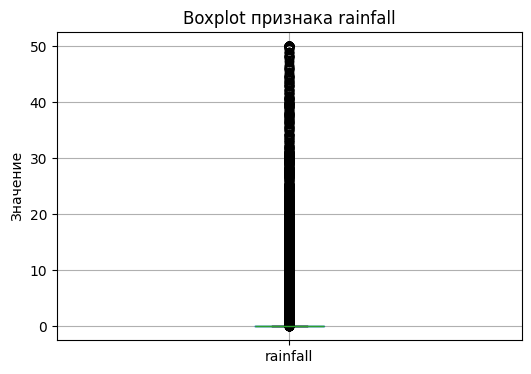

In [ ]:
column = "rainfall"
df.boxplot(column=column, figsize=(6, 4))
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение")
plt.show()

### Очистка выбросов

In [ ]:
cols = ["humidity", "rainfall", "soil_moisture", "soil_ph", "fertilizer_used"]

bounds = {}
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    bounds[col] = (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

In [ ]:
for col in cols:
    low, up = bounds[col]
    mask = (df[col] < low) | (df[col] > up)
    print(f"{col:15s} | выбросов: {mask.sum():5d} ({mask.mean()*100:5.2f}%)")

humidity        | выбросов:    43 ( 0.43%)
rainfall        | выбросов:  2318 (23.18%)
soil_moisture   | выбросов:    57 ( 0.57%)
soil_ph         | выбросов:    14 ( 0.14%)
fertilizer_used | выбросов:    37 ( 0.37%)


In [ ]:
for col in ["humidity", "soil_moisture", "soil_ph", "fertilizer_used"]:
    low, up = bounds[col]
    mask = (df[col] < low) | (df[col] > up)
    print(f"{col:20s} | anomaly_flag=1 среди выбросов: {df.loc[mask, 'anomaly_flag'].mean():.2%}")

humidity             | anomaly_flag=1 среди выбросов: 6.98%
soil_moisture        | anomaly_flag=1 среди выбросов: 3.51%
soil_ph              | anomaly_flag=1 среди выбросов: 0.00%
fertilizer_used      | anomaly_flag=1 среди выбросов: 2.70%


In [ ]:
for col in ["humidity", "soil_moisture", "soil_ph", "fertilizer_used"]:
    low, up = bounds[col]
    n = ((df[col] < low) | (df[col] > up)).sum()
    df[col] = df[col].clip(low, up)
    print(f"{col:20s} | зажато значений: {n}")

humidity             | зажато значений: 43
soil_moisture        | зажато значений: 57
soil_ph              | зажато значений: 14
fertilizer_used      | зажато значений: 37


In [ ]:
for col in cols:
    low, up = bounds[col]
    n = ((df[col] < low) | (df[col] > up)).sum()
    print(f"{col:20s} | осталось выбросов: {n}")

humidity             | осталось выбросов: 0
rainfall             | осталось выбросов: 2318
soil_moisture        | осталось выбросов: 0
soil_ph              | осталось выбросов: 0
fertilizer_used      | осталось выбросов: 0


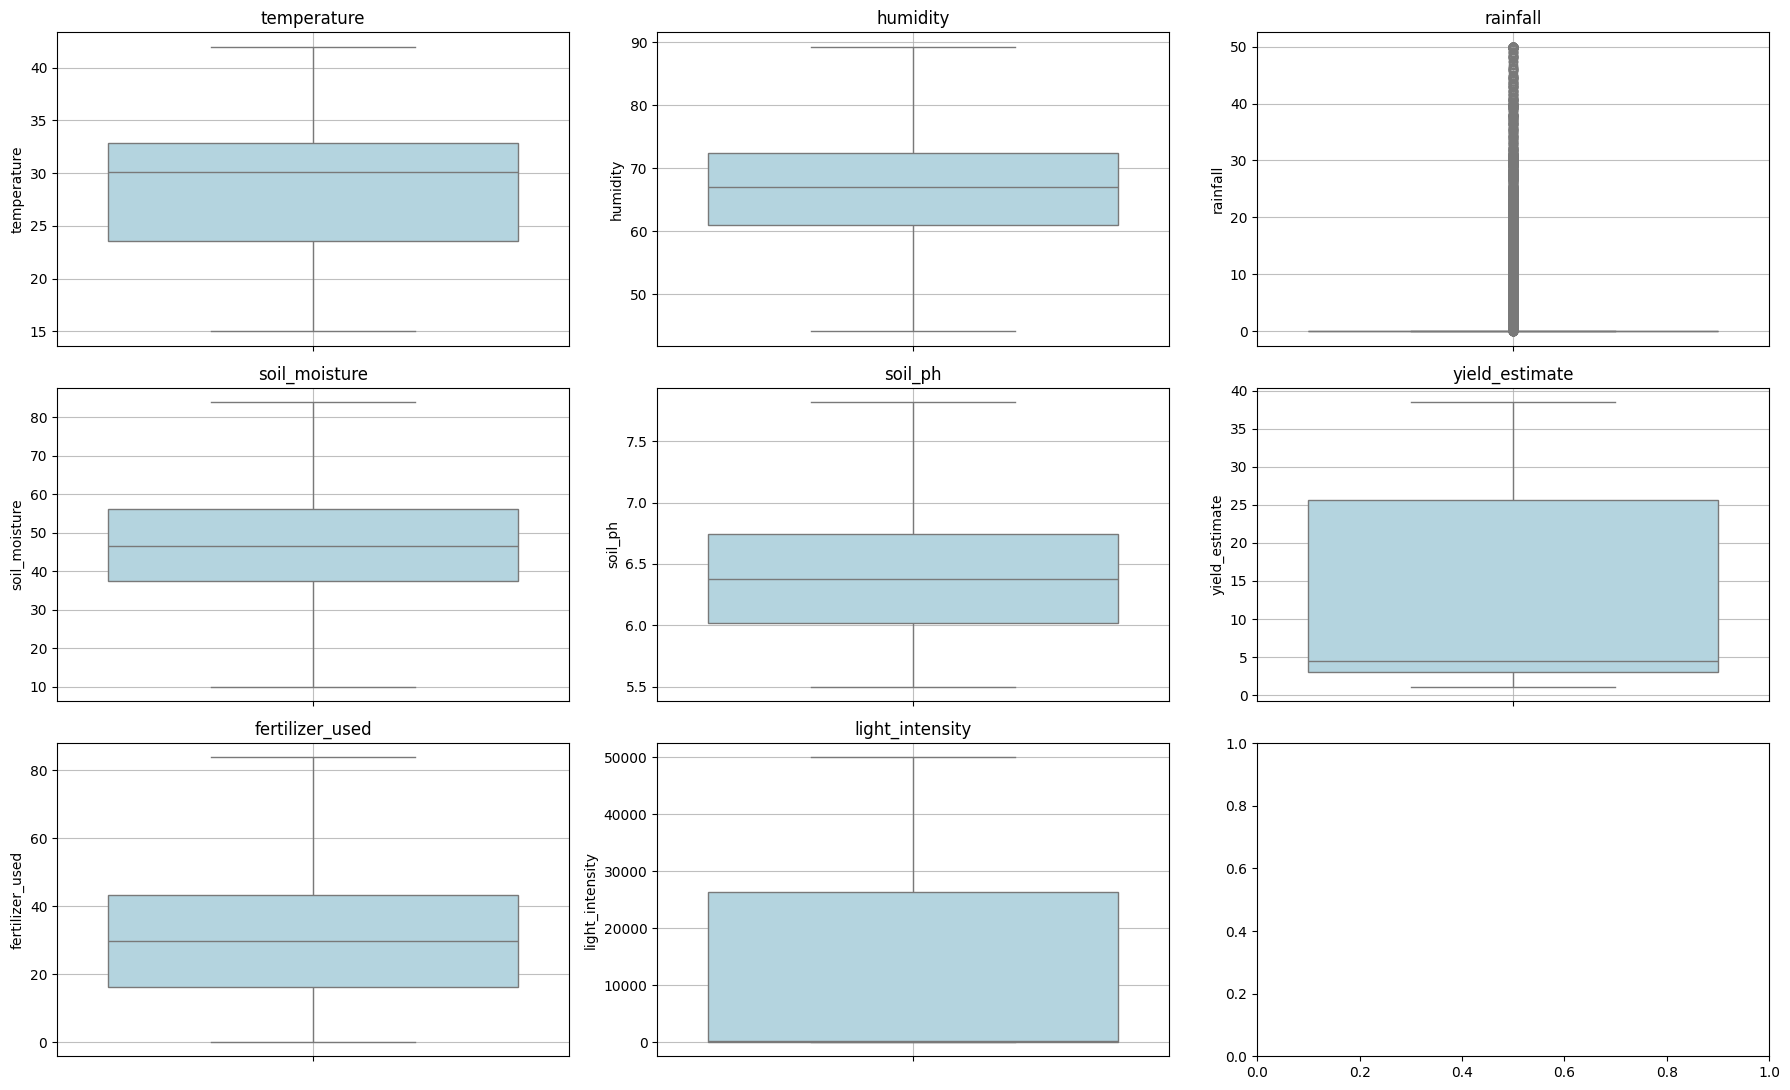

In [ ]:
cols = ["temperature", "humidity", "rainfall",
        "soil_moisture", "soil_ph", "yield_estimate", "fertilizer_used", "light_intensity"]

fig, axes = plt.subplots(3, 3, figsize=(18, 11))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(y=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
    ax.grid(True, alpha=0.8)

plt.tight_layout()
plt.show()

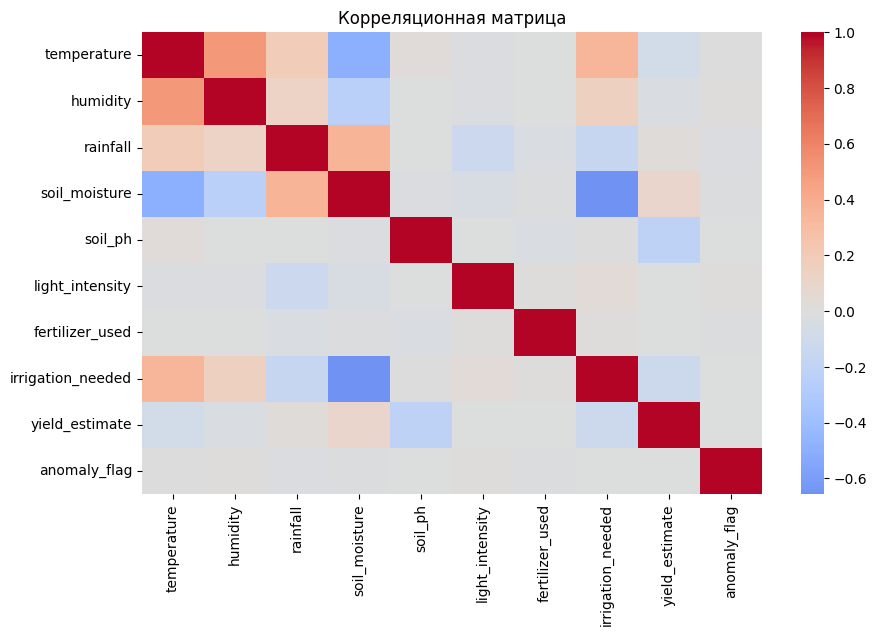

In [ ]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Корреляционная матрица")
plt.show()

### Итог аудита

In [4]:
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())
print("=" * 50)
print("ВЫБРОСЫ")
print("=" * 50)
for col in ["humidity", "rainfall", "soil_moisture", "soil_ph", "fertilizer_used"]:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    low, up = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df[col] < low) | (df[col] > up)).sum()
    print(f"{col:20s} | {n:5d} ({n/len(df)*100:5.2f}%)")

print("=" * 50)
print("БАЛАНС КЛАССОВ crop_health")
print("=" * 50)
print(df["crop_health"].value_counts(normalize=True).round(4) * 100)

print("=" * 50)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ")
print("=" * 50)
df.describe()

Количество строк: 10000
Количество столбцов: 17
Пропущенных ячеек: 0
Полных дубликатов: 0
ВЫБРОСЫ
humidity             |    43 ( 0.43%)
rainfall             |  2318 (23.18%)
soil_moisture        |    57 ( 0.57%)
soil_ph              |    14 ( 0.14%)
fertilizer_used      |    37 ( 0.37%)
БАЛАНС КЛАССОВ crop_health
crop_health
Healthy     74.18
Stressed    20.34
Critical     5.48
Name: proportion, dtype: float64
СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ


,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,yield_estimate,anomaly_flag
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,28.618411,66.692239,3.019284,47.019202,6.380495,12188.731100,30.521662,0.181500,13.134026,0.020200
std,5.399040,8.178572,8.151775,13.748611,0.502964,15317.903602,18.900354,0.385451,12.929829,0.140691
min,15.000000,40.000000,0.000000,10.000000,5.500000,0.000000,0.000000,0.000000,1.120000,0.000000
25%,23.520000,61.070000,0.000000,37.560000,6.020000,42.000000,16.280000,0.000000,3.040000,0.000000
50%,30.150000,67.010000,0.000000,46.660000,6.380000,97.000000,29.820000,0.000000,4.450000,0.000000
75%,32.890000,72.380000,0.000000,56.142500,6.740000,26307.500000,43.262500,0.000000,25.590000,0.000000
max,42.000000,95.000000,50.000000,95.000000,8.090000,50000.000000,101.130000,1.000000,38.500000,1.000000


Датасет представляет собой синтетический, но реалистично смоделированный набор данных о состоянии окружающей среды в Бангладеш. Он содержит 10 000 часовых наблюдений с 17 признаками: атмосферные условия, характеристики почвы, агротехнические показатели и продуктивность. Датасет демонстрирует физически осмысленные корреляции, суточные и сезонные циклы, а также реалистичный дисбаланс классов целевой переменной crop_health (74% Healthy, 20% Stressed, 5% Critical). Выбросы малочисленны (0.14–0.57% для четырёх признаков) и не связаны с меткой anomaly_flag, что говорит об их природном, а не аномальном характере. rainfall имеет 23% формальных «выбросов», отражающих реальные ливни, и не подлежит удалению. Пропусков и дубликатов в датасете не было.